# 06 · How Much Should the Summer Shift Move?

**Project:** Industrial Load Shifting · **Author:** Swaroop Jadhav

### Purpose
In notebook 04 I chose a summer schedule that starts the shift **4 hours later** from April to September,
because +4 h gave the biggest saving *for the shift lever alone*. But the two levers are not independent:
the standby switch-off window moves together with the shift (decision D15), so a later shift also changes
how much standby can be switched off. Here I check the **combined** saving for every option, to see if +4 h
is really the best choice, and how sensitive the result is.

### Questions
1. How does the total saving (standby off + summer shift) change with 0 to +6 hours?
2. Is April–September the right summer, or would a shorter or longer season be better?
3. What is the smallest shift that still gets almost all of the saving?

**Prerequisites:** same data as notebook 05.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent / "src"))
import co2
import config
import cost
import forecast as fc
import optimise as op

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 12,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight")

loads = pd.read_csv(config.SPARK_LOAD_FILE, parse_dates=["timestamp_utc"])
prices = pd.read_csv(config.PRICES_RAW_FILE, parse_dates=["timestamp_utc"])
generation = pd.read_csv(config.GENERATION_FILE, parse_dates=["timestamp_utc"])

In [2]:
aligned = cost.align_load_to_prices(loads, prices)
machines = aligned.attrs["machines"]
intensity = co2.intensity(generation)
ci_matrix = co2.intensity_matrix(intensity)
price_m = fc.price_matrix(prices)
baseline_eur = cost.baseline_cost(aligned).loc["TOTAL", "cost_eur"]

classes = op.classify_machines(aligned)
movable = classes.index[classes["type"] != "continuous"].tolist()
energy = op.production_matrix(aligned, movable)
energy_cost = op.matrix_cost(energy, price_m).sum()
energy_co2 = co2.emissions_t(energy, ci_matrix)


def combined_saving(hours, months):
    """Standby off + summer shift for one option. The standby window moves with the shift."""
    offsets = op.seasonal_offsets(energy.index, hours, months)
    shifted = op.apply_offsets(energy, offsets)
    shift_eur = energy_cost - op.matrix_cost(shifted, price_m).sum()
    shift_co2 = energy_co2 - co2.emissions_t(shifted, ci_matrix)
    standby_eur, standby_co2 = 0.0, 0.0
    for m in machines:
        removed = op.standby_removed_kwh(aligned, m, shift_offsets=offsets)
        standby_eur += float((removed / 1000 * aligned["price_eur_mwh"]).sum())
        standby_co2 += co2.emissions_series_t(removed, aligned, intensity)
    return {"shift_eur": shift_eur, "standby_eur": standby_eur, "total_eur": shift_eur + standby_eur,
            "co2_saved_t": shift_co2 + standby_co2}


seasons = {"Apr–Sep (6 months)": range(4, 10), "May–Aug (4 months)": range(5, 9), "Mar–Oct (8 months)": range(3, 11)}
rows = []
for season, months in seasons.items():
    for hours in range(0, 7):
        rows.append({"season": season, "hours_later": hours, **combined_saving(hours, months)})
sens = pd.DataFrame(rows)
sens["total_pct_of_bill"] = 100 * sens["total_eur"] / baseline_eur
sens.round(1)

,season,hours_later,shift_eur,standby_eur,total_eur,co2_saved_t,total_pct_of_bill
0,Apr–Sep (6 months),0,0.0,3064.4,3064.4,10.2,29.0
1,Apr–Sep (6 months),1,117.4,3071.5,3188.8,10.7,30.2
2,Apr–Sep (6 months),2,227.8,3051.2,3279.0,11.1,31.0
3,Apr–Sep (6 months),3,308.9,3003.8,3312.7,11.3,31.3
4,Apr–Sep (6 months),4,337.4,2960.3,3297.7,11.3,31.2
5,Apr–Sep (6 months),5,285.8,2937.5,3223.3,11.1,30.5
6,Apr–Sep (6 months),6,151.9,2924.6,3076.5,10.8,29.1
7,May–Aug (4 months),0,0.0,3064.4,3064.4,10.2,29.0
8,May–Aug (4 months),1,73.1,3074.2,3147.3,10.6,29.8
9,May–Aug (4 months),2,140.2,3067.1,3207.3,10.8,30.3


---
## Part A · Total saving for every shift option

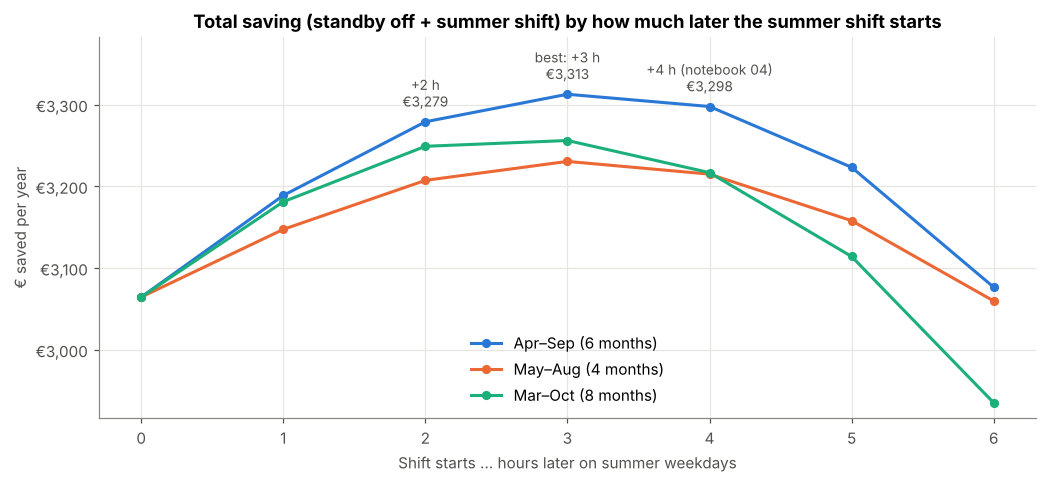

In [3]:
fig, ax = plt.subplots()
for i, (season, g) in enumerate(sens.groupby("season", sort=False)):
    ax.plot(g["hours_later"], g["total_eur"], color=COLORS[i], marker="o", markersize=5, label=season)
apr_g = sens[sens["season"].str.startswith("Apr")].set_index("hours_later")
for h, text in [(2, "+2 h"), (3, "best: +3 h"), (4, "+4 h (notebook 04)")]:
    ax.annotate(f"{text}\n€{apr_g.loc[h, 'total_eur']:,.0f}", (h, apr_g.loc[h, "total_eur"]),
                textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9, color="#52514e")
ax.set_ylim(top=sens["total_eur"].max() + 70)
ax.set(title="Total saving (standby off + summer shift) by how much later the summer shift starts",
       xlabel="Shift starts … hours later on summer weekdays", ylabel="€ saved per year",
       xticks=range(0, 7))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"€{x:,.0f}"))
ax.legend(frameon=False, loc="lower center")
save(fig, "W6_A_summer_shift_sensitivity")
plt.show()

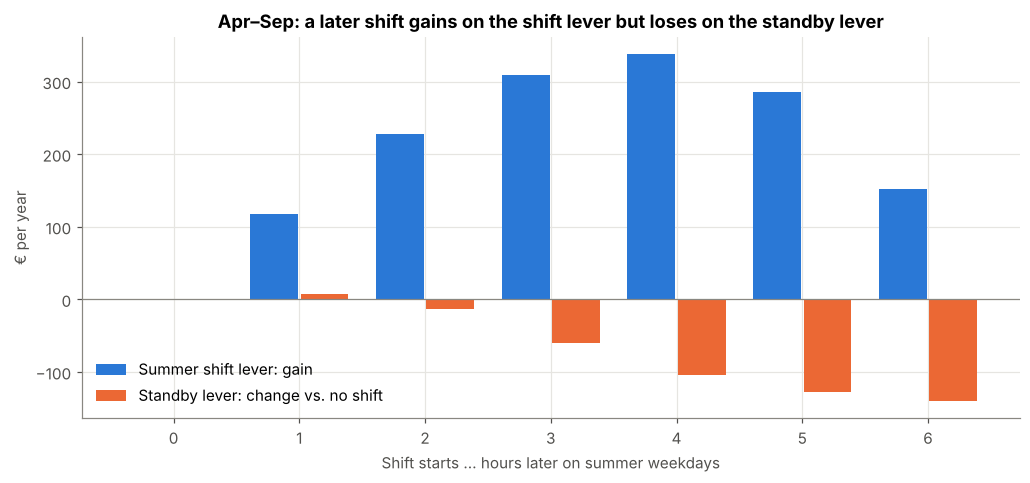

Best option: +3 h → €3,313 per year
+2 h: €3,279 (99% of best), CO₂ saved 11.1 t
+3 h: €3,313 (100% of best), CO₂ saved 11.3 t
+4 h: €3,298 (100% of best), CO₂ saved 11.3 t


In [4]:
apr = sens[sens["season"].str.startswith("Apr")].set_index("hours_later")
parts = pd.DataFrame({
    "shift lever gain": apr["shift_eur"],
    "standby lever change": apr["standby_eur"] - apr.loc[0, "standby_eur"],
})
fig, ax = plt.subplots()
x = np.arange(len(parts))
ax.bar(x - 0.2, parts["shift lever gain"], width=0.38, color=COLORS[0], label="Summer shift lever: gain")
ax.bar(x + 0.2, parts["standby lever change"], width=0.38, color=COLORS[1], label="Standby lever: change vs. no shift")
ax.axhline(0, color="#898781", linewidth=0.8)
ax.set_axisbelow(True)
ax.set(title="Apr–Sep: a later shift gains on the shift lever but loses on the standby lever",
       xlabel="Shift starts … hours later on summer weekdays", ylabel="€ per year", xticks=x)
ax.legend(frameon=False, loc="lower left")
save(fig, "W6_B_lever_trade_off")
plt.show()

best = apr["total_eur"].idxmax()
print(f"Best option: +{best} h → €{apr.loc[best, 'total_eur']:,.0f} per year")
for h in (2, 3, 4):
    print(f"+{h} h: €{apr.loc[h, 'total_eur']:,.0f} ({100 * apr.loc[h, 'total_eur'] / apr.loc[best, 'total_eur']:.0f}% of best), "
          f"CO₂ saved {apr.loc[h, 'co2_saved_t']:.1f} t")

**Interpretation**

When I looked at the summer shift alone in notebook 04, +4 h was the best option with €337 per year. But when I add the standby lever, the picture changes a bit. The later the shift starts, the later the machines have to stay on in the evening, and summer evenings are the most expensive hours of the day. At the same time they can be switched off in the early morning, which is cheaper. So the standby lever loses money with every hour of shift: with +4 h it saves €104 less than without any shift. Part of what the shift lever wins is lost again on the standby side.

Because of this, the best combined option is +3 h with €3,313 per year, not +4 h (€3,298). But honestly the curve is very flat between +2 h and +4 h: +2 h gives €3,279, which is 99% of the best option and only €19 less than the +4 h plan from notebook 04. The CO₂ saving is also almost the same (11.1 t vs 11.3 t). After +4 h the saving drops quickly, because then the shift moves into the expensive evening hours.

April to September is the best season. May to August is too short and misses a lot of sunny days, and March to October adds months where midday is not much cheaper than the morning, so the shift and the standby lever both get worse.

For the plant manager this is actually good news. A shift that starts 2 hours later (about 06:00–07:00 instead of 04:00–05:00) is much easier to agree with the workers than 4 hours later, and it gets almost the full saving. So I would start with +2 h, and only go further if the workers prefer a later start anyway.

---
## Key findings

1. The two levers interact: a later shift keeps standby machines on into the expensive summer evenings, so the standby lever saves less (−€104 per year at +4 h).
2. The best combined option is +3 h (€3,313 per year), but the saving is almost flat between +2 h and +4 h (€3,279–3,313).
3. A +2 h summer shift gets 99% of the best saving and is much easier to introduce than +4 h, so it is the better first step.
4. April–September is the best summer season; a shorter (May–Aug) or longer (Mar–Oct) season saves less.
5. Lesson for me: optimising each lever separately can give a slightly wrong answer, the levers have to be checked together.